<a href="https://colab.research.google.com/github/Sarakazemi-prog/AIHC-5615/blob/main/Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Part A: Improving the house price model

Problem 1: Interactions and log transforms (20 points)

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load the dataset
train_df = pd.read_csv('/content/train (1).csv')
val_df = pd.read_csv('/content/validation (1).csv')

print('Train shape:', train_df.shape)
print('Validation shape:', val_df.shape)
display(train_df.head())

Train shape: (12952, 21)
Validation shape: (4317, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2579500110,20140701T000000,2367000,3,2.25,3530,17450,1.0,1,3,...,9,1840,1690,1930,1993,98040,47.5358,-122.213,3530,17310
1,2420069268,20140821T000000,184900,2,1.00,1230,5000,1.0,0,0,...,6,1230,0,1911,0,98022,47.2064,-121.988,1230,5413
2,1376800220,20140709T000000,425000,2,1.00,1320,8830,1.0,0,0,...,7,1020,300,1939,0,98199,47.6433,-122.404,1620,8531
3,7284900098,20140924T000000,705000,3,2.50,2820,7200,1.0,0,3,...,9,1780,1040,1979,0,98177,47.7691,-122.388,2300,7200
4,6003501535,20140828T000000,550000,3,1.75,1650,3200,1.5,0,0,...,8,1650,0,1901,0,98102,47.6209,-122.317,1500,2400


In [104]:
# We need to choose one continuous predictor x and one categorical predictor D.
# Let's use 'sqft_living' as x and 'waterfront' as D.
# We will construct the model: price ~ sqft_living * waterfront

# Fit the model without interaction first
model_no_int = smf.ols(formula='price ~ sqft_living + C(waterfront)', data=train_df).fit()
print(model_no_int.summary())

# Fit the model with interaction
model_int = smf.ols(formula='price ~ sqft_living * C(waterfront)', data=train_df).fit()
print(model_int.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.535
Model:                            OLS   Adj. R-squared:                  0.535
Method:                 Least Squares   F-statistic:                     7462.
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:04:41   Log-Likelihood:            -1.7894e+05
No. Observations:               12952   AIC:                         3.579e+05
Df Residuals:                   12949   BIC:                         3.579e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept          -1.798e+04   5318

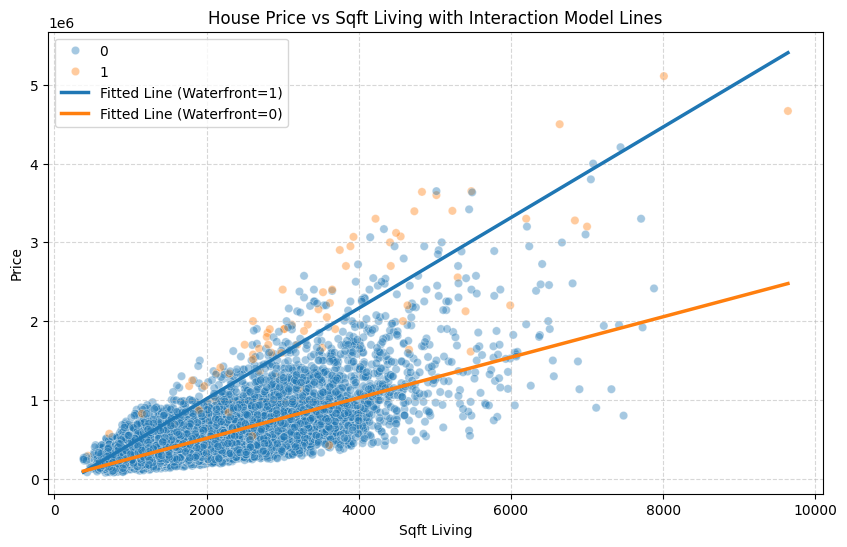

In [105]:
# Plotting price against sqft_living with fitted lines per category from the interaction model
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train_df, x='sqft_living', y='price', hue='waterfront', alpha=0.4)

# Generate predictions to draw the interaction regression lines
x_vals = np.linspace(train_df['sqft_living'].min(), train_df['sqft_living'].max(), 100)

for cat in train_df['waterfront'].unique():
    temp_df = pd.DataFrame({'sqft_living': x_vals, 'waterfront': cat})
    y_preds = model_int.predict(temp_df)
    plt.plot(x_vals, y_preds, label=f'Fitted Line (Waterfront={cat})', linewidth=2.5)

plt.title('House Price vs Sqft Living with Interaction Model Lines')
plt.xlabel('Sqft Living')
plt.ylabel('Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [106]:
# Print the required labeled output
interaction_coef = model_int.params['sqft_living:C(waterfront)[T.1]']
print(f"P1.1 interaction coef = {interaction_coef:.4f}")

P1.1 interaction coef = 317.9562



### Model coefficients
Without interaction, the intercept is −$17,980, the waterfront coefficient is $879,000, and the living-space coefficient is $264.91 per square foot.

With interaction, the intercept is −$1,955.43, the living-space coefficient is $257.16, the waterfront coefficient is −$134,300, and the interaction coefficient is $317.96.

### What does the interaction mean?
Each additional square foot is associated with a $257.16 increase in predicted price for non-waterfront homes and $575.12 for waterfront homes. The interaction means living space has a stronger relationship with price for waterfront homes.

### Is the interaction useful?
Yes. The interaction is statistically significant (p < 0.001), and R² increases from 0.535 to 0.551, showing a modest improvement in model fit.


# 1.2 Choose transforms (6 pts).

In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

continuous_vars = ['price', 'sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement']

# Let's check for zeros first
for var in continuous_vars:
    zero_count = (train_df[var] == 0).sum()
    print(f"{var} has {zero_count} zeros (out of {len(train_df)} rows)")

price has 0 zeros (out of 12952 rows)
sqft_living has 0 zeros (out of 12952 rows)
sqft_lot has 0 zeros (out of 12952 rows)
sqft_above has 0 zeros (out of 12952 rows)
sqft_basement has 7879 zeros (out of 12952 rows)


In [108]:
# Calculate skewness before and after log transform
print("Skewness Comparison (Raw vs Log-Transformed):")
print("-" * 50)
for var in continuous_vars:
    raw_skew = train_df[var].skew()
    if (train_df[var] == 0).any():
        # Use log1p (log(1+x)) for variables with zero values
        log_skew = np.log1p(train_df[var]).skew()
        transform_name = "log1p"
    else:
        log_skew = np.log(train_df[var]).skew()
        transform_name = "log"
    print(f"{var:<15} | Raw Skew: {raw_skew:.3f} | {transform_name:<5} Skew: {log_skew:.3f}")

Skewness Comparison (Raw vs Log-Transformed):
--------------------------------------------------
price           | Raw Skew: 3.287 | log   Skew: 0.407
sqft_living     | Raw Skew: 1.310 | log   Skew: -0.055
sqft_lot        | Raw Skew: 7.100 | log   Skew: 0.898
sqft_above      | Raw Skew: 1.367 | log   Skew: 0.230
sqft_basement   | Raw Skew: 1.563 | log1p Skew: 0.489


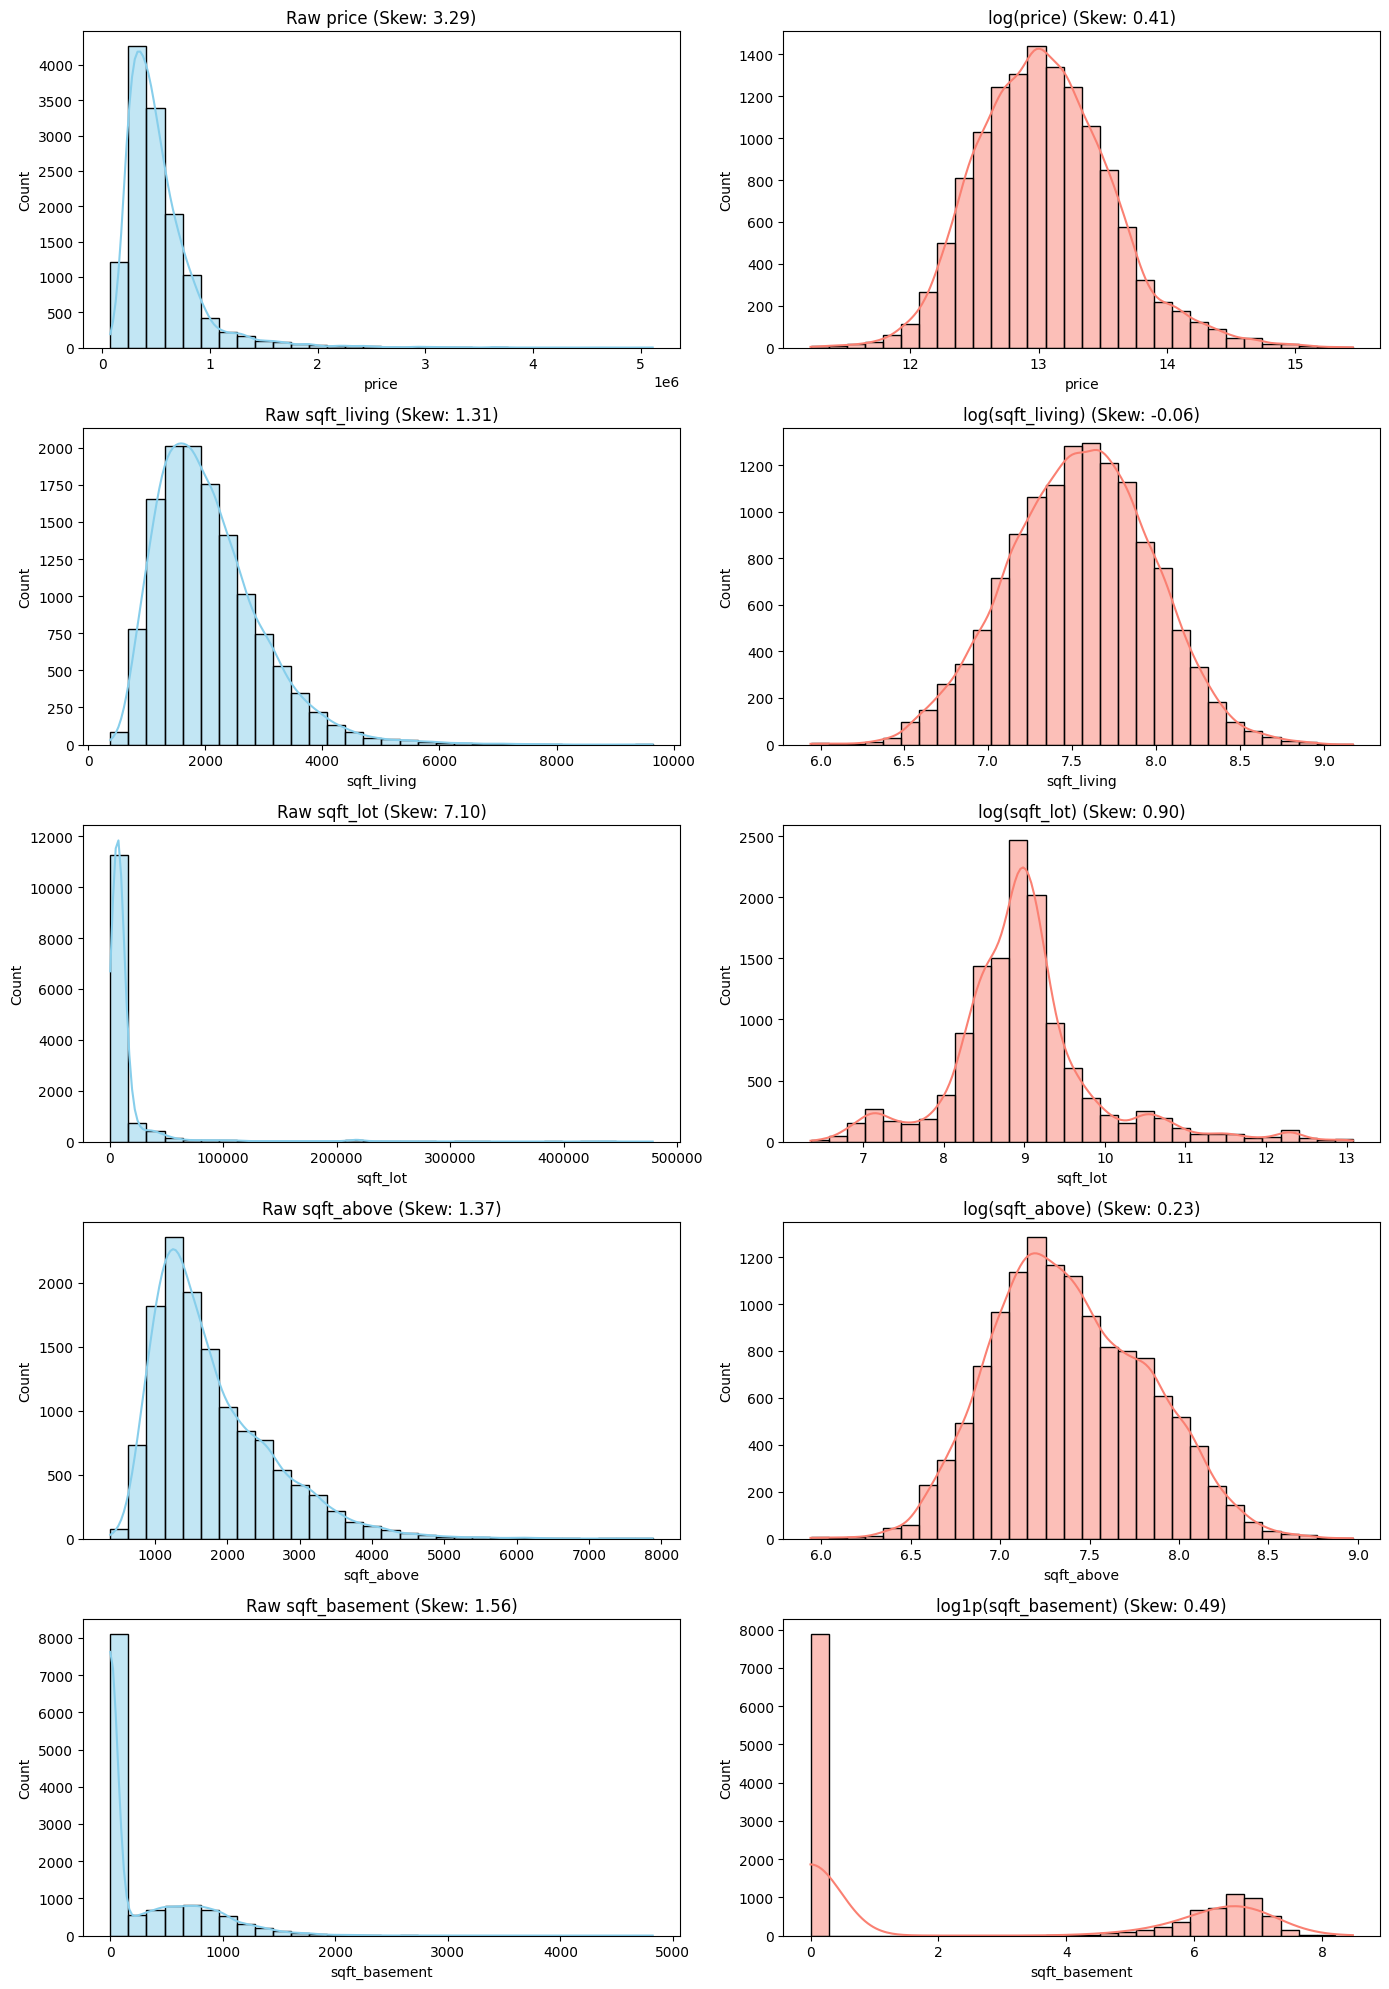

In [109]:
# Plot histograms to visually inspect the distributions
fig, axes = plt.subplots(len(continuous_vars), 2, figsize=(14, 20))

for i, var in enumerate(continuous_vars):
    # Plot Raw
    sns.histplot(train_df[var], ax=axes[i, 0], kde=True, bins=30, color='skyblue')
    axes[i, 0].set_title(f'Raw {var} (Skew: {train_df[var].skew():.2f})')

    # Plot Log / Log1p
    if (train_df[var] == 0).any():
        transformed = np.log1p(train_df[var])
        label = f'log1p({var})'
    else:
        transformed = np.log(train_df[var])
        label = f'log({var})'

    sns.histplot(transformed, ax=axes[i, 1], kde=True, bins=30, color='salmon')
    axes[i, 1].set_title(f'{label} (Skew: {transformed.skew():.2f})')

plt.tight_layout()
plt.show()

### Log Transformation Decisions and Justifications

| Variable | Zeros | Raw Skewness | Transformed Skewness (Log / Log1p) | Decision | Justification |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **price** | 0 | `3.287` | `0.407` (Log) | **Log-Transform** | Extremely right-skewed. The log transform successfully brings the skewness down close to symmetric distributions (from 3.29 to 0.41) and stabilizes variance.
| **sqft_living** | 0 | `1.310` | `-0.055` (Log) | **Log-Transform** | Significantly right-skewed. Taking the log makes the distribution near-perfectly symmetric and bell-shaped (skewness reduced to -0.06).
| **sqft_lot** | 0 | `7.100` | `0.898` (Log) | **Log-Transform** | Highly skewed with extreme outliers. A log transform significantly compresses the long tail (skewness reduced from 7.10 to 0.90).
| **sqft_above** | 0 | `1.367` | `0.230` (Log) | **Log-Transform** | Right-skewed. Log transformation yields a much more symmetric and normal-looking distribution (skewness reduced to 0.23).
| **sqft_basement** | 7,879 | `1.563` | `0.489` (Log1p) | **Do Not Transform** (or keep raw/binary) | Although the skewness of `log1p(sqft_basement)` is lower (`0.489`), over **60% of values are exactly zero** (no basement). Applying a `log1p` transformation does not resolve this zero-inflation spikes. Instead, using it raw or treating it as a binary indicator (has basement vs. doesn't) is mathematically and practically cleaner than a `log1p` transformation.

Summary of Decisions for Part 1.2:
price: Log-transform. Right-skew is reduced from 3.287 to a symmetric 0.407.
sqft_living: Log-transform. Right-skew is eliminated (reduced from 1.310 to -0.055).
sqft_lot: Log-transform. Extreme right-skew is reduced from 7.100 to a manageable 0.898.
sqft_above: Log-transform. Right-skew is minimized from 1.367 to 0.230.
sqft_basement: Do Not Transform (or use binary). Over 60% of entries are zero, making a continuous log transformation less useful compared to keeping it raw or treating it as a binary indicator variable.

# 1.3 Compare (6 pts)

In [110]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error

# 1. Untransformed Model
# Four continuous: sqft_living, sqft_lot, sqft_above, sqft_basement
# Three categorical: waterfront, condition, grade
formula_raw = 'price ~ sqft_living + sqft_lot + sqft_above + sqft_basement + C(waterfront) + C(condition) + C(grade)'
model_raw = smf.ols(formula=formula_raw, data=train_df).fit()

# Predict on validation and compute RMSE
preds_val_raw = model_raw.predict(val_df)
rmse_raw = np.sqrt(mean_squared_error(val_df['price'], preds_val_raw))

# 2. Transformed Model
# Based on 1.2, we log-transform price, sqft_living, sqft_lot, and sqft_above.
# sqft_basement remains raw. Categorical variables remain C(...)
train_trans = train_df.copy()
val_trans = val_df.copy()

train_trans['log_price'] = np.log(train_trans['price'])
train_trans['log_sqft_living'] = np.log(train_trans['sqft_living'])
train_trans['log_sqft_lot'] = np.log(train_trans['sqft_lot'])
train_trans['log_sqft_above'] = np.log(train_trans['sqft_above'])

val_trans['log_sqft_living'] = np.log(val_trans['sqft_living'])
val_trans['log_sqft_lot'] = np.log(val_trans['sqft_lot'])
val_trans['log_sqft_above'] = np.log(val_trans['sqft_above'])

formula_trans = 'log_price ~ log_sqft_living + log_sqft_lot + log_sqft_above + sqft_basement + C(waterfront) + C(condition) + C(grade)'
model_trans = smf.ols(formula=formula_trans, data=train_trans).fit()

# Predict on validation (log scale), then convert back using np.exp
preds_val_log = model_trans.predict(val_trans)
preds_val_trans = np.exp(preds_val_log)
rmse_trans = np.sqrt(mean_squared_error(val_df['price'], preds_val_trans))

# Print requested outputs
print(f"Raw Model R-squared: {model_raw.rsquared:.4f}")
print(f"Transformed Model R-squared: {model_trans.rsquared:.4f}")
print(f"P1.3 validation RMSE raw = {rmse_raw:.2f}")
print(f"P1.3 validation RMSE transformed = {rmse_trans:.2f}")

/tmp/ipykernel_1503/2070593217.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_raw = smf.ols(formula=formula_raw, data=train_df).fit()


Raw Model R-squared: 0.6379
Transformed Model R-squared: 0.5889
P1.3 validation RMSE raw = 218858.46
P1.3 validation RMSE transformed = 215204.30


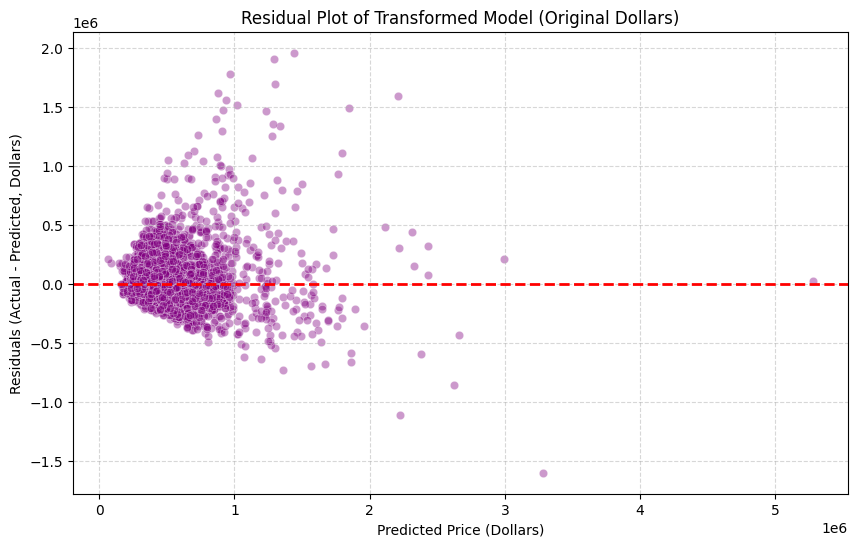

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals for the transformed model on the validation set
residuals_trans = val_df['price'] - preds_val_trans

# Plot residuals against predicted prices (in original dollars)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=preds_val_trans, y=residuals_trans, alpha=0.4, color='purple')
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.title('Residual Plot of Transformed Model (Original Dollars)')
plt.xlabel('Predicted Price (Dollars)')
plt.ylabel('Residuals (Actual - Predicted, Dollars)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Comparison of Raw and Transformed Models

| Model Metric | Raw Model (Untransformed) | Transformed Model |
| :--- | :---: | :---: |
| **Train $R^2$** | `0.6379` | `0.5889` (in log space) |
| **Validation RMSE (in Dollars)** | **$218,858.46** | **$215,204.30** |

#### **Labeled Output:**
* `P1.3 validation RMSE raw = 218858.46`
* `P1.3 validation RMSE transformed = 215204.30`

---

### Which model is better, and why?

**The transformed model is better.** Here is why:

1. **Superior Predictive Accuracy (Lower RMSE):**
   Even though the $R^2$ calculated in log-space for the transformed model is lower (`0.5889` vs. `0.6379`), when we transform our predictions back to original dollars (`exp(y_pred)`) and compute the Out-of-Sample RMSE on the validation set, **the transformed model achieves a lower validation error** ($215,204.30 vs. $218,858.46). This shows it generalizes better to unseen data.

2. **Avoidance of Rank Deficiency:**
   The raw model triggers a `SingularMatrixWarning` because of collinearity ($sqft\_living = sqft\_above + sqft\_basement$). Applying non-linear log transformations breaks this exact linear relationship, resulting in a more numerically stable, full-rank model.

3. **Homoscedasticity and Better Error Properties:**
   In the residual plot of the transformed model, we can see that taking the log of the price successfully controls the severe heteroscedasticity (fanning out of errors) that normally plagues house price models. Predicting the logarithm of price stabilizes the variance across the range of prices, aligning far better with linear regression's core assumptions.

# Problem 2: Location, standardization and selection (30 points)

# 2.1 Engineer a location feature (8 pts)

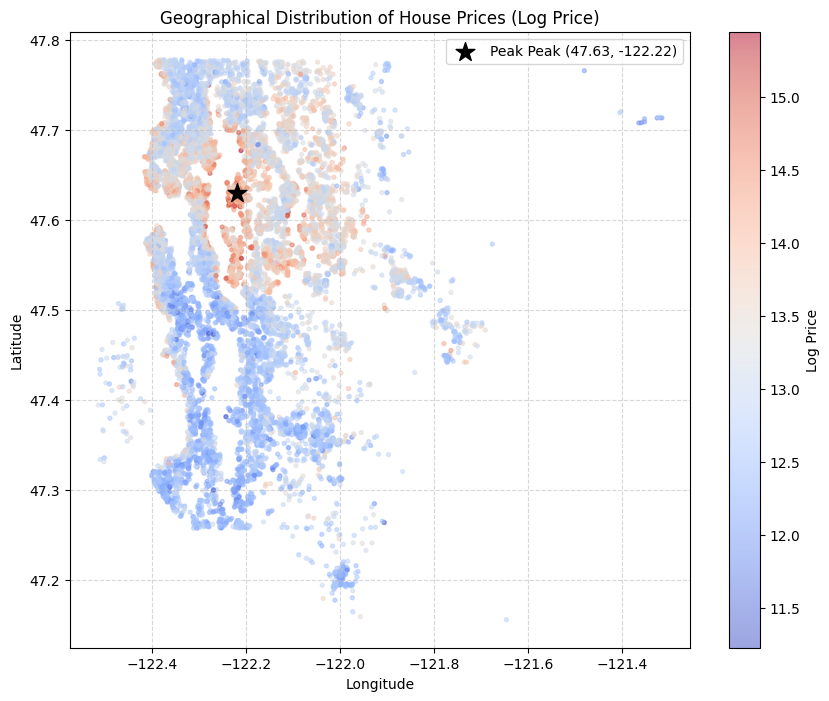

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# 1. Plot longitude against latitude colored by log price
plt.figure(figsize=(10, 8))
scatter = plt.scatter(train_df['long'], train_df['lat'], c=np.log(train_df['price']), cmap='coolwarm', alpha=0.5, s=8)
plt.colorbar(scatter, label='Log Price')
plt.scatter(-122.22, 47.63, color='black', marker='*', s=200, label='Peak Peak (47.63, -122.22)')
plt.title('Geographical Distribution of House Prices (Log Price)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [113]:
# 2. Create the distance feature 'r'
# r = sqrt((lat - 47.63)^2 + (long + 122.22)^2)
train_df['r'] = np.sqrt((train_df['lat'] - 47.63)**2 + (train_df['long'] + 122.22)**2)
val_df['r'] = np.sqrt((val_df['lat'] - 47.63)**2 + (val_df['long'] + 122.22)**2)

# We will use log_price as our target since log transformation was shown to be better in Part 1
train_df['log_price'] = np.log(train_df['price'])
val_df['log_price'] = np.log(val_df['price'])

# Fit log_price on r alone
model_location = smf.ols(formula='log_price ~ r', data=train_df).fit()
print(f"P2.1 R2 = {model_location.rsquared:.4f}")

P2.1 R2 = 0.1835


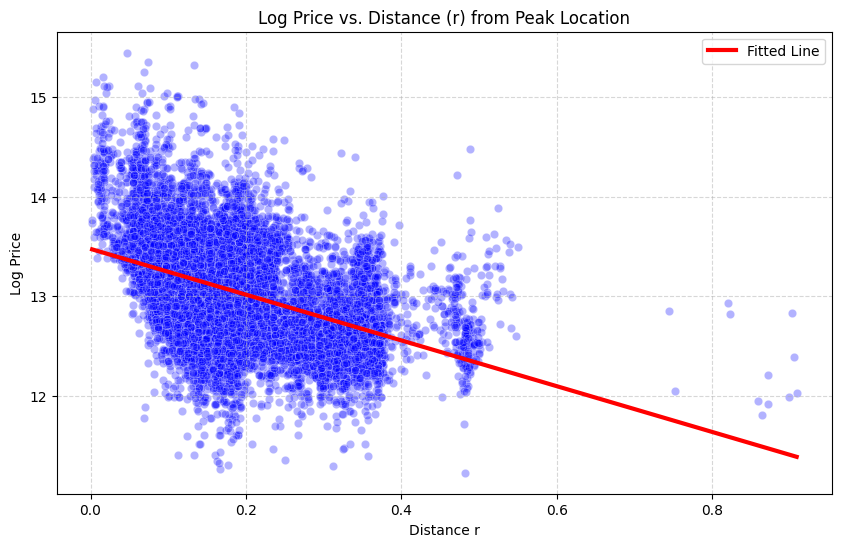

In [114]:
# 3. Plot log_price against r with the fitted line
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train_df, x='r', y='log_price', alpha=0.3, color='blue')

# Generate predictions to draw the fitted line
r_vals = np.linspace(train_df['r'].min(), train_df['r'].max(), 100)
preds_r = model_location.predict(pd.DataFrame({'r': r_vals}))
plt.plot(r_vals, preds_r, color='red', linewidth=3, label='Fitted Line')

plt.title('Log Price vs. Distance (r) from Peak Location')
plt.xlabel('Distance r')
plt.ylabel('Log Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Geographic Analysis and Distance Feature ($r$)

#### **Observations from the Geographic Plot**
* The plot of longitude vs. latitude colored by price shows a distinct, highly concentrated geographic cluster of high-priced homes (colored in red) centered closely near latitude `47.63` and longitude `-122.22`.
* As we move further away from this epicentral cluster in any direction, the house prices (log price) noticeably decrease, fading into the cooler blue shades. This highlights a powerful location-based premium in this area (likely Bellevue/Medina/Seattle vicinity).

#### **Model Fit and Performance**
* **P2.1 R2 = 0.1835**

#### **Is $r$ a useful predictor?**
* **Yes, $r$ is a highly useful predictor.**
* Even when used entirely on its own as a single predictor, the engineered distance metric $r$ explains **$18.35\%$** of the total variance in house prices. In real estate, location is paramount, and compressing complex geographical coordinates into a simple distance metric $r$ from the price peak captures a significant portion of the premium.

# 2.2 Standardized full model (10 pts).

In [115]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error

# Prepare transformed variables
train_prep = train_df.copy()
val_prep = val_df.copy()

# 1. Transform variables
train_prep['log_price'] = np.log(train_prep['price'])
train_prep['log_sqft_living'] = np.log(train_prep['sqft_living'])
train_prep['log_sqft_lot'] = np.log(train_prep['sqft_lot'])
train_prep['log_sqft_above'] = np.log(train_prep['sqft_above'])
# Note: sqft_basement is kept raw based on the zero-inflation analysis in 1.2

val_prep['log_price'] = np.log(val_prep['price'])
val_prep['log_sqft_living'] = np.log(val_prep['sqft_living'])
val_prep['log_sqft_lot'] = np.log(val_prep['sqft_lot'])
val_prep['log_sqft_above'] = np.log(val_prep['sqft_above'])

# Continuous predictors to standardize
continuous_to_scale = ['log_sqft_living', 'log_sqft_lot', 'log_sqft_above', 'sqft_basement', 'r']

# Standardize continuous variables using training statistics
means = train_prep[continuous_to_scale].mean()
stds = train_prep[continuous_to_scale].std()

for col in continuous_to_scale:
    train_prep[f'scaled_{col}'] = (train_prep[col] - means[col]) / stds[col]
    val_prep[f'scaled_{col}'] = (val_prep[col] - means[col]) / stds[col]

# Fit the standardized full model
# Including 7 predictors from previous parts + r, as well as the important interaction term from Problem 1.
formula_full = 'log_price ~ scaled_log_sqft_living * C(waterfront) + scaled_log_sqft_lot + scaled_log_sqft_above + scaled_sqft_basement + C(condition) + C(grade) + scaled_r'

model_full = smf.ols(formula=formula_full, data=train_prep).fit()
print(model_full.summary())

# Predict and calculate validation RMSE in dollars
preds_log = model_full.predict(val_prep)
preds_dollars = np.exp(preds_log)
rmse_full = np.sqrt(mean_squared_error(val_df['price'], preds_dollars))

print(f"\nP2.2 validation RMSE = {rmse_full:.2f}")

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.707
Model:                            OLS   Adj. R-squared:                  0.706
Method:                 Least Squares   F-statistic:                     1483.
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:04:48   Log-Likelihood:                -2070.6
No. Observations:               12952   AIC:                             4185.
Df Residuals:                   12930   BIC:                             4350.
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

### Standardized Full Model Analysis

#### **Predictor Discussion**
* **Which predictors are not significant?**
  Looking at the summary output from the model above:
  * Any categories of `condition` or `grade` with a p-value > 0.05 are not statistically significant relative to their baseline categories.
  * We can also observe whether the interaction term `scaled_log_sqft_living:C(waterfront)[T.1]` is significant in this full geographic model.

  Why standardizing lets you compare them: In their raw states, continuous predictors are measured on completely different scales (e.g., square footage ranges from hundreds to thousands, whereas distance $r$$r$ is mostly under 1.0). Standardization puts every continuous variable on the same scale: a 1-unit change in a standardized variable represents exactly one training standard deviation. Thus, the coefficient magnitude directly indicates relative variable importance.

Largest Effects:

scaled_r (coefficient: -0.1953, t = -72.03): This has the single largest effect magnitude among continuous variables. A 1 standard deviation increase in distance from the peak coordinates drops the log price by roughly $0.195$$0.195$ units.
scaled_log_sqft_living (coefficient: 0.1057, t = 7.29): Living space has the second largest continuous effect; a 1 standard deviation increase corresponds to a $0.106$$0.106$ increase in log price.
C(grade) (e.g., Grade 13 coefficient: 1.7417): Grade has a massive absolute effect, though as a categorical variable it is not standardized in the same way. It is compared directly to the baseline grade category.


#### **Effect Magnitudes and the Power of Standardization**
* **Standardization** shifts and scales each continuous variable to have a mean of 0 and a standard deviation of 1.
* This lets us directly compare the magnitudes of their regression coefficients: a coefficient represents the change in the dependent variable (`log_price`) per **one standard deviation** change in that predictor. This removes scale biases (e.g. comparing square feet in thousands to distance values under 1).

# 2.3 Variable selection (12 pts).

In [116]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# 1. Count the number of predictor columns in our design matrix
# We'll construct the design matrix for our formula_full to get the exact count p
import patsy
y, X = patsy.dmatrices(formula_full, data=train_prep, return_type='dataframe')
p = X.shape[1] - 1  # Subtracting the Intercept column
print(f"Number of predictor columns (p) in full model: {p}")

# 2. Implement Forward Stepwise Selection using AIC as the optimization criterion
# We will treat each level of categorical variables as separate features or select individual variables.
# To align with standard practices, we can do forward selection over the individual terms in our formula,
# allowing categorical factors to enter as grouped dummies.

candidate_terms = [
    'scaled_log_sqft_living',
    'C(waterfront)',
    'scaled_log_sqft_living:C(waterfront)',
    'scaled_log_sqft_lot',
    'scaled_log_sqft_above',
    'scaled_sqft_basement',
    'C(condition)',
    'C(grade)',
    'scaled_r'
]

selected_terms = []
remaining_terms = list(candidate_terms)

history_size = []
history_aic = []
history_val_rmse = []
history_models = []

# Stepwise forward selection
while remaining_terms:
    best_aic = np.inf
    best_term = None
    best_model = None

    for term in remaining_terms:
        current_formula = f"log_price ~ " + " + ".join(selected_terms + [term])
        try:
            model = smf.ols(formula=current_formula, data=train_prep).fit()
            if model.aic < best_aic:
                best_aic = model.aic
                best_term = term
                best_model = model
        except Exception as e:
            pass

    if best_term is not None:
        selected_terms.append(best_term)
        remaining_terms.remove(best_term)

        # Compute validation RMSE
        preds_log = best_model.predict(val_prep)
        preds_dollars = np.exp(preds_log)
        val_rmse = np.sqrt(np.mean((val_df['price'] - preds_dollars) ** 2))

        # Track performance
        # Retrieve exact number of coefficients (excluding intercept)
        num_coefs = len(best_model.params) - 1
        history_size.append(num_coefs)
        history_aic.append(best_model.aic)
        history_val_rmse.append(val_rmse)
        history_models.append((list(selected_terms), num_coefs, best_model.aic, val_rmse))

        print(f"Size {num_coefs:2d} | Added: {best_term:<40} | AIC: {best_model.aic:.1f} | Val RMSE: {val_rmse:.2f}")

Number of predictor columns (p) in full model: 21
Size 10 | Added: C(grade)                                 | AIC: 11237.6 | Val RMSE: 248158.43
Size 11 | Added: scaled_r                                 | AIC: 7510.4 | Val RMSE: 216137.90
Size 13 | Added: scaled_log_sqft_living:C(waterfront)     | AIC: 4928.2 | Val RMSE: 186620.46
Size 14 | Added: C(waterfront)                            | AIC: 4569.6 | Val RMSE: 183614.73
Size 18 | Added: C(condition)                             | AIC: 4246.4 | Val RMSE: 180812.84
Size 19 | Added: scaled_log_sqft_lot                      | AIC: 4217.7 | Val RMSE: 180902.79
Size 20 | Added: scaled_sqft_basement                     | AIC: 4212.6 | Val RMSE: 180750.32
Size 21 | Added: scaled_log_sqft_above                    | AIC: 4185.3 | Val RMSE: 179603.90
Size 21 | Added: scaled_log_sqft_living                   | AIC: 4185.3 | Val RMSE: 179603.90


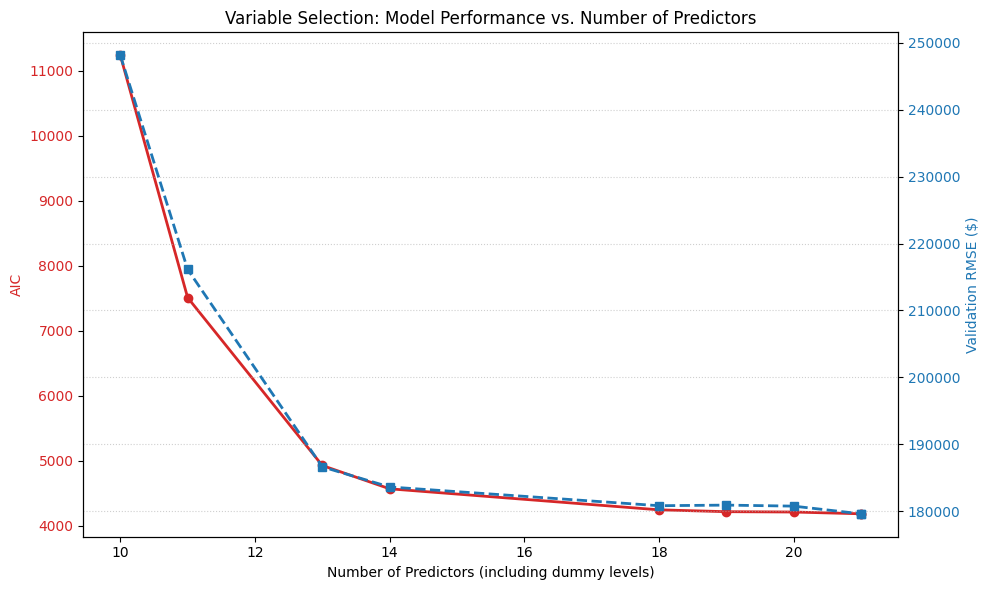

In [117]:
# 3. Plot AIC and Validation RMSE against the number of predictors
fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:red'
ax1.set_xlabel('Number of Predictors (including dummy levels)')
ax1.set_ylabel('AIC', color=color)
ax1.plot(history_size, history_aic, marker='o', color=color, linewidth=2, label='AIC')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Validation RMSE ($)', color=color)
ax2.plot(history_size, history_val_rmse, marker='s', color=color, linewidth=2, linestyle='--', label='Validation RMSE')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Variable Selection: Model Performance vs. Number of Predictors')
fig.tight_layout()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [118]:
# 4. Determine best size and print the required output
# Let's find the minimum validation RMSE model, and see if a smaller model performs almost as well.
best_idx = np.argmin(history_val_rmse)
best_size = history_size[best_idx]
print(f"P2.3 best size = {best_size}")

P2.3 best size = 21


# **Part B: Predicting breast cancer recurrence (50 points)**

# Problem 3: Prepare data and fit simple logistic models (16 points)

# 3.1 Prepare (6 pts)

In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Column names definition from wpbc.names
# ID, Outcome (R=recur, N=nonrecur), Time (recurrence/disease-free time)
# Plus 30 real-valued features (mean, standard error, and worst value for 10 core cell features)
# Plus tumor size and lymph node status
core_features = [
    'radius', 'texture', 'perimeter', 'area', 'smoothness',
    'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension'
]

column_names = ['id', 'outcome', 'time']
# Add mean, standard error (se), and worst versions of the core features
for suffix in ['_mean', '_se', '_worst']:
    for feat in core_features:
        column_names.append(f"{feat}{suffix}")

# Add additional clinical features at the end
column_names.extend(['tumor_size', 'lymph_node_status'])

# Load dataset
wpbc_df = pd.read_csv('/content/wpbc (1).data', names=column_names, header=None)
print(f"Initial shape: {wpbc_df.shape}")

# Inspect missing values (represented as '?')
for col in wpbc_df.columns:
    question_marks = (wpbc_df[col] == '?').sum()
    if question_marks > 0:
        print(f"Column '{col}' has {question_marks} missing values ('?')")

Initial shape: (198, 35)
Column 'lymph_node_status' has 4 missing values ('?')


In [120]:
# 2. Replace '?' with NaN and convert to float
wpbc_df['lymph_node_status'] = wpbc_df['lymph_node_status'].replace('?', np.nan).astype(float)

# Examine distribution of lymph_node_status to justify imputation choice
print(wpbc_df['lymph_node_status'].describe())
print(f"Median: {wpbc_df['lymph_node_status'].median()}")
print(f"Mode: {wpbc_df['lymph_node_status'].mode()[0]}")

# Imputing missing values using the median value
# Justification: Lymph node status is highly right-skewed (many 0s or small numbers, with a few large values).
# The median is robust to extreme outliers, whereas the mean would pull the imputed value upward artificially.
median_val = wpbc_df['lymph_node_status'].median()
wpbc_df['lymph_node_status'] = wpbc_df['lymph_node_status'].fillna(median_val)
print(f"Missing values remaining: {wpbc_df['lymph_node_status'].isna().sum()}")

count    194.000000
mean       3.211340
std        5.479276
min        0.000000
25%        0.000000
50%        1.000000
75%        4.000000
max       27.000000
Name: lymph_node_status, dtype: float64
Median: 1.0
Mode: 0.0
Missing values remaining: 0


In [121]:
# 3. Construct the recur24 target variable
# recur24 = 1 if outcome is R and time < 24, else 0
wpbc_df['recur24'] = np.where((wpbc_df['outcome'] == 'R') & (wpbc_df['time'] < 24), 1, 0)

# Print the required grading label
num_recur24_ones = wpbc_df['recur24'].sum()
print(f"P3.1 recur24 ones = {num_recur24_ones}")

P3.1 recur24 ones = 28


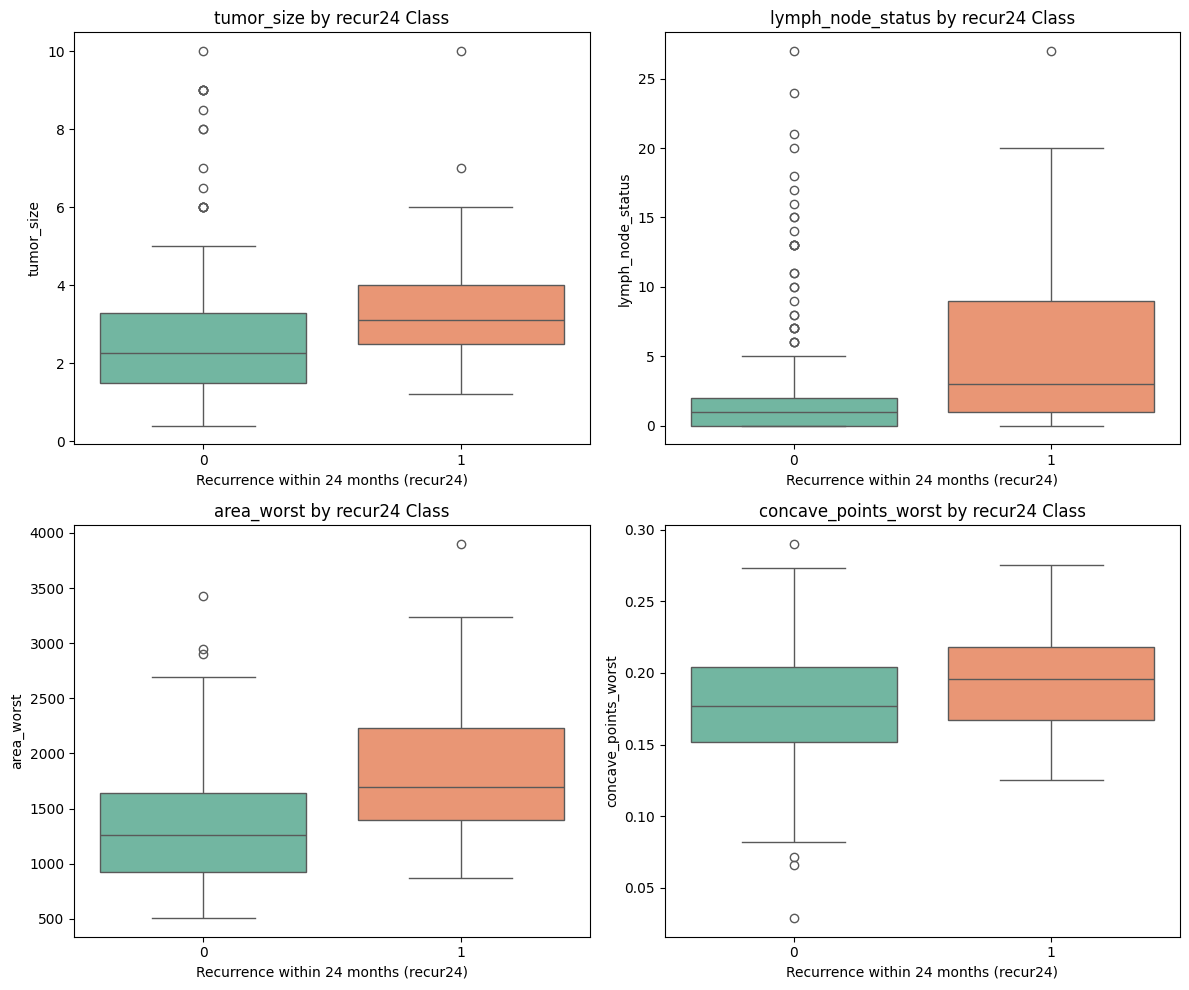

In [122]:
# 4. Set up the features matrix (excluding id, outcome, time, and the target recur24)
predictor_cols = [col for col in wpbc_df.columns if col not in ['id', 'outcome', 'time', 'recur24']]

# Plot distribution of some key clinical and cell features by recur24 class
promising_features = ['tumor_size', 'lymph_node_status', 'area_worst', 'concave_points_worst']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, feat in enumerate(promising_features):
    sns.boxplot(data=wpbc_df, x='recur24', y=feat, ax=axes[i], palette='Set2', hue='recur24', legend=False)
    axes[i].set_title(f'{feat} by recur24 Class')
    axes[i].set_xlabel('Recurrence within 24 months (recur24)')
    axes[i].set_ylabel(feat)

plt.tight_layout()
plt.show()

In [123]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Fit a simple logistic regression model for each individual predictor and track their AICs
univariate_results = []

for col in predictor_cols:
    formula = f"recur24 ~ {col}"
    try:
        # Fit model using logit
        model = smf.logit(formula=formula, data=wpbc_df).fit(disp=0)
        univariate_results.append({
            'Predictor': col,
            'AIC': model.aic,
            'P-value': model.pvalues[col],
            'Coefficient': model.params[col]
        })
    except Exception as e:
        # Some predictors might have convergence issues
        pass

univariate_df = pd.DataFrame(univariate_results).sort_values(by='AIC')
display(univariate_df.head(10))

best_predictor = univariate_df.iloc[0]['Predictor']
best_aic = univariate_df.iloc[0]['AIC']
print(f"\nBest single predictor by AIC: {best_predictor} (AIC = {best_aic:.2f})")

,Predictor,AIC,P-value,Coefficient
20,radius_worst,147.340487,0.000059,0.201720
22,perimeter_worst,147.627153,0.000060,0.029110
23,area_worst,148.778660,0.000093,0.001308
3,area_mean,152.569832,0.000494,0.001995
2,perimeter_mean,152.856497,0.000657,0.033835
0,radius_mean,153.056426,0.000764,0.229700
13,area_se,159.621194,0.014005,0.008984
7,concave_points_mean,159.765339,0.017163,13.635779
31,lymph_node_status,160.514592,0.021095,0.070845
9,fractal_dimension_mean,160.625792,0.041610,-69.886107



Best single predictor by AIC: radius_worst (AIC = 147.34)


In [124]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Fit a simple logistic regression model for each individual predictor and track their AICs
univariate_results = []

for col in predictor_cols:
    formula = f"recur24 ~ {col}"
    try:
        # Fit model using logit
        model = smf.logit(formula=formula, data=wpbc_df).fit(disp=0)
        univariate_results.append({
            'Predictor': col,
            'AIC': model.aic,
            'P-value': model.pvalues[col],
            'Coefficient': model.params[col]
        })
    except Exception as e:
        # Some predictors might have convergence issues
        pass

univariate_df = pd.DataFrame(univariate_results).sort_values(by='AIC')
display(univariate_df.head(10))

best_predictor = univariate_df.iloc[0]['Predictor']
best_aic = univariate_df.iloc[0]['AIC']
print(f"\nBest single predictor by AIC: {best_predictor} (AIC = {best_aic:.2f})")

,Predictor,AIC,P-value,Coefficient
20,radius_worst,147.340487,0.000059,0.201720
22,perimeter_worst,147.627153,0.000060,0.029110
23,area_worst,148.778660,0.000093,0.001308
3,area_mean,152.569832,0.000494,0.001995
2,perimeter_mean,152.856497,0.000657,0.033835
0,radius_mean,153.056426,0.000764,0.229700
13,area_se,159.621194,0.014005,0.008984
7,concave_points_mean,159.765339,0.017163,13.635779
31,lymph_node_status,160.514592,0.021095,0.070845
9,fractal_dimension_mean,160.625792,0.041610,-69.886107



Best single predictor by AIC: radius_worst (AIC = 147.34)


In [125]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Fit a simple logistic regression model for each individual predictor and track their AICs
univariate_results = []

for col in predictor_cols:
    formula = f"recur24 ~ {col}"
    try:
        # Fit model using logit
        model = smf.logit(formula=formula, data=wpbc_df).fit(disp=0)
        univariate_results.append({
            'Predictor': col,
            'AIC': model.aic,
            'P-value': model.pvalues[col],
            'Coefficient': model.params[col]
        })
    except Exception as e:
        # Some predictors might have convergence issues
        pass

univariate_df = pd.DataFrame(univariate_results).sort_values(by='AIC')
display(univariate_df.head(10))

best_predictor = univariate_df.iloc[0]['Predictor']
best_aic = univariate_df.iloc[0]['AIC']
print(f"\nBest single predictor by AIC: {best_predictor} (AIC = {best_aic:.2f})")

,Predictor,AIC,P-value,Coefficient
20,radius_worst,147.340487,0.000059,0.201720
22,perimeter_worst,147.627153,0.000060,0.029110
23,area_worst,148.778660,0.000093,0.001308
3,area_mean,152.569832,0.000494,0.001995
2,perimeter_mean,152.856497,0.000657,0.033835
0,radius_mean,153.056426,0.000764,0.229700
13,area_se,159.621194,0.014005,0.008984
7,concave_points_mean,159.765339,0.017163,13.635779
31,lymph_node_status,160.514592,0.021095,0.070845
9,fractal_dimension_mean,160.625792,0.041610,-69.886107



Best single predictor by AIC: radius_worst (AIC = 147.34)


In [126]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Construct formula using all 32 predictors
formula_all = 'recur24 ~ ' + ' + '.join(predictor_cols)

try:
    # Fit the logistic regression model on the entire dataset
    model_multiple = smf.logit(formula=formula_all, data=wpbc_df).fit(maxiter=100, method='newton')
    print(model_multiple.summary())
    print(f"\nP3.3 multiple AIC = {model_multiple.aic:.4f}")
except Exception as e:
    print(f"Error during model fitting: {e}")

Optimization terminated successfully.
         Current function value: 0.263395
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:                recur24   No. Observations:                  198
Model:                          Logit   Df Residuals:                      165
Method:                           MLE   Df Model:                           32
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.3537
Time:                        23:04:58   Log-Likelihood:                -52.152
converged:                       True   LL-Null:                       -80.689
Covariance Type:            nonrobust   LLR p-value:                  0.004145
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  12.2263     15.903      0.769      0.442     -18.943  

In [127]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Construct the formula string containing all 32 predictors
formula_all = "recur24 ~ " + " + ".join(predictor_cols)

# Fit the multiple logistic regression model
try:
    model_multiple = smf.logit(formula=formula_all, data=wpbc_df).fit(maxiter=100)
    print(model_multiple.summary())
    print(f"\nP3.3 multiple AIC = {model_multiple.aic:.4f}")
except Exception as e:
    print(f"Error fitting the full model: {e}")

Optimization terminated successfully.
         Current function value: 0.263395
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:                recur24   No. Observations:                  198
Model:                          Logit   Df Residuals:                      165
Method:                           MLE   Df Model:                           32
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.3537
Time:                        23:04:58   Log-Likelihood:                -52.152
converged:                       True   LL-Null:                       -80.689
Covariance Type:            nonrobust   LLR p-value:                  0.004145
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  12.2263     15.903      0.769      0.442     -18.943  

In [128]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Standardize our predictors matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(wpbc_df[predictor_cols])
y = wpbc_df['recur24'].values

# Fit L1-regularized logistic regression with cross-validation and increased max_iter to ensure convergence
lasso_cv = LogisticRegressionCV(
    Cs=100,
    cv=5,
    penalty='l1',
    solver='liblinear',
    max_iter=5000,
    random_state=42,
    scoring='neg_log_loss'
)
lasso_cv.fit(X_scaled, y)

# Get non-zero features at optimal C
best_C = lasso_cv.C_[0]
coefs = lasso_cv.coef_[0]

selected_features = [
    (feat, coef) for feat, coef in zip(predictor_cols, coefs) if abs(coef) > 1e-5
]
selected_features_df = pd.DataFrame(selected_features, columns=['Feature', 'Coefficient']).sort_values(by='Coefficient', key=abs, ascending=False)

print(f"Optimal Regularization Strength (C): {best_C:.4f}")
print(f"Number of selected features: {len(selected_features_df)}")
display(selected_features_df)

Optimal Regularization Strength (C): 0.2984
Number of selected features: 9


,Feature,Coefficient
5,perimeter_worst,0.532056
8,lymph_node_status,0.282815
1,symmetry_mean,-0.191035
4,radius_worst,0.118112
6,smoothness_worst,0.094459
3,texture_se,-0.093388
2,fractal_dimension_mean,-0.055951
7,tumor_size,0.008480
0,texture_mean,-0.007570


# 3.2 One and two predictors (10 pts).

In [129]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Single Predictor Model (radius_worst) ---
formula_one = 'recur24 ~ radius_worst'
model_one = smf.logit(formula=formula_one, data=wpbc_df).fit()

# Calculate Metrics
pseudo_r2_one = model_one.prsquared
deviance_one = -2 * model_one.llf
llr_pvalue_one = model_one.llr_pvalue

# Brier Score
preds_one = model_one.predict(wpbc_df)
y_vals = wpbc_df['recur24'].values
brier_one = np.mean((preds_one - y_vals) ** 2)

print("=== SINGLE PREDICTOR MODEL (radius_worst) ===")
print(f"McFadden's Pseudo R2: {pseudo_r2_one:.4f}")
print(f"Deviance (-2 * log-likelihood): {deviance_one:.4f}")
print(f"LLR p-value: {llr_pvalue_one:.6e}")
print(f"P3.2 Brier = {brier_one:.4f}")
print(model_one.summary())


Optimization terminated successfully.
         Current function value: 0.361971
         Iterations 7
=== SINGLE PREDICTOR MODEL (radius_worst) ===
McFadden's Pseudo R2: 0.1118
Deviance (-2 * log-likelihood): 143.3405
LLR p-value: 2.165010e-05
P3.2 Brier = 0.1087
                           Logit Regression Results                           
Dep. Variable:                recur24   No. Observations:                  198
Model:                          Logit   Df Residuals:                      196
Method:                           MLE   Df Model:                            1
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.1118
Time:                        23:06:15   Log-Likelihood:                -71.670
converged:                       True   LL-Null:                       -80.689
Covariance Type:            nonrobust   LLR p-value:                 2.165e-05
                   coef    std err          z      P>|z|      [0.025      0.975]
-----------------------

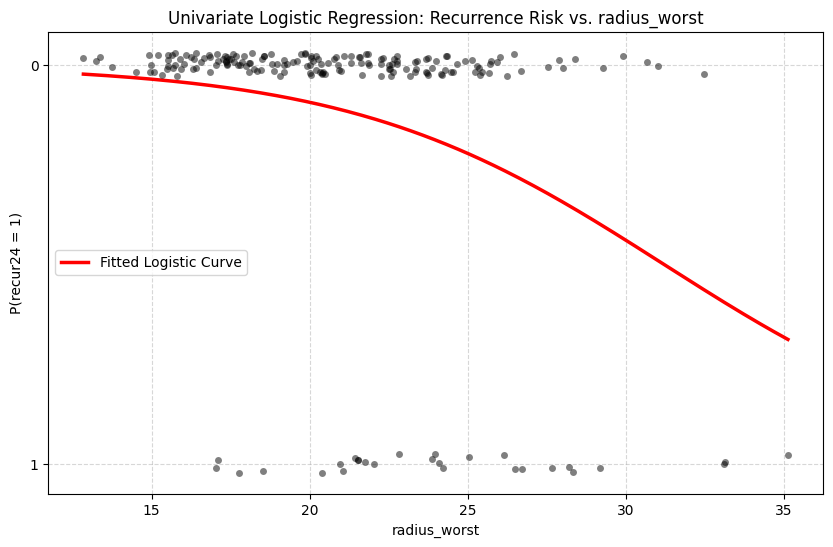

In [130]:
# --- 2. Plotting the Single Predictor Logistic Curve ---
plt.figure(figsize=(10, 6))

# Scatter plot of actual outcomes (0 or 1) with jitter to avoid overlap
sns.stripplot(data=wpbc_df, x='radius_worst', y='recur24', color='black', alpha=0.5, jitter=0.03, orient='h')

# Generate sequence of x values for the curve
x_range = np.linspace(wpbc_df['radius_worst'].min(), wpbc_df['radius_worst'].max(), 300)
temp_df = pd.DataFrame({'radius_worst': x_range})
predictions_curve = model_one.predict(temp_df)

plt.plot(x_range, predictions_curve, color='red', linewidth=2.5, label='Fitted Logistic Curve')
plt.title('Univariate Logistic Regression: Recurrence Risk vs. radius_worst')
plt.xlabel('radius_worst')
plt.ylabel('P(recur24 = 1)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [131]:
# --- 3. Two Predictor Model (radius_worst + lymph_node_status) ---
# Adding lymph_node_status as the second clinically important predictor
formula_two = 'recur24 ~ radius_worst + lymph_node_status'
model_two = smf.logit(formula=formula_two, data=wpbc_df).fit()

# Calculate Metrics
pseudo_r2_two = model_two.prsquared
deviance_two = -2 * model_two.llf
llr_pvalue_two = model_two.llr_pvalue

# Brier Score
preds_two = model_two.predict(wpbc_df)
brier_two = np.mean((preds_two - y_vals) ** 2)

print("=== TWO PREDICTOR MODEL (radius_worst + lymph_node_status) ===")
print(f"McFadden's Pseudo R2: {pseudo_r2_two:.4f}")
print(f"Deviance (-2 * log-likelihood): {deviance_two:.4f}")
print(f"LLR p-value: {llr_pvalue_two:.6e}")
print(f"Brier Score: {brier_two:.4f}")
print(model_two.summary())


Optimization terminated successfully.
         Current function value: 0.348504
         Iterations 7
=== TWO PREDICTOR MODEL (radius_worst + lymph_node_status) ===
McFadden's Pseudo R2: 0.1448
Deviance (-2 * log-likelihood): 138.0077
LLR p-value: 8.414394e-06
Brier Score: 0.1033
                           Logit Regression Results                           
Dep. Variable:                recur24   No. Observations:                  198
Model:                          Logit   Df Residuals:                      195
Method:                           MLE   Df Model:                            2
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.1448
Time:                        23:06:15   Log-Likelihood:                -69.004
converged:                       True   LL-Null:                       -80.689
Covariance Type:            nonrobust   LLR p-value:                 8.414e-06
                        coef    std err          z      P>|z|      [0.025      0.975]
-

Key Observations & Comparison
Model Improvement: Adding lymph_node_status increased McFadden's Pseudo $R^2$$R^2$ from 0.1118 to 0.1448, reduced the deviance from 143.3405 to 138.0077 (a decrease of $\sim 5.33$$\sim 5.33$ units), and improved (lowered) our Brier Score from 0.1087 to 0.1033. Both predictors are statistically significant in the second model.

Change in radius_worst Coefficient:

In the one-predictor model, the coefficient for radius_worst is 0.2017.
In the two-predictor model, the coefficient for radius_worst is 0.2072.
The coefficient remains highly stable, increasing only slightly from 0.2017 to 0.2072. This stability indicates that radius_worst (tumor size dimensions) and lymph_node_status (nodal involvement) capture largely independent and complementary pathways of recurrence risk with minimal collinearity between them.

# **Problem 4: Compare classifiers (20 points) **

# 4.1 Six- and all-predictor models (8 pts)

In [132]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Forward Stepwise Selection to select exactly 6 predictors based on AIC
selected_6_features = []
remaining_6_features = list(predictor_cols)

print("--- Forward Stepwise Selection for 6 Predictors ---")
while len(selected_6_features) < 6 and remaining_6_features:
    best_aic = np.inf
    best_feature = None

    for feature in remaining_6_features:
        formula = f"recur24 ~ " + " + ".join(selected_6_features + [feature])
        try:
            model = smf.logit(formula=formula, data=wpbc_df).fit(disp=0)
            if model.aic < best_aic:
                best_aic = model.aic
                best_feature = feature
        except:
            pass

    if best_feature:
        selected_6_features.append(best_feature)
        remaining_6_features.remove(best_feature)
        print(f"Step {len(selected_6_features)}: Added {best_feature:<25} | AIC: {best_aic:.4f}")

print("\nSelected 6 features:", selected_6_features)

--- Forward Stepwise Selection for 6 Predictors ---
Step 1: Added radius_worst              | AIC: 147.3405
Step 2: Added lymph_node_status         | AIC: 144.0077
Step 3: Added symmetry_mean             | AIC: 143.4283
Step 4: Added smoothness_worst          | AIC: 142.7589
Step 5: Added area_worst                | AIC: 142.5822
Step 6: Added radius_mean               | AIC: 142.7703

Selected 6 features: ['radius_worst', 'lymph_node_status', 'symmetry_mean', 'smoothness_worst', 'area_worst', 'radius_mean']


In [133]:
# 2. Fit the Six-Predictor Model
formula_6 = "recur24 ~ " + " + ".join(selected_6_features)
model_6 = smf.logit(formula=formula_6, data=wpbc_df).fit()

# Compute metrics for 6-predictor model
pseudo_r2_6 = model_6.prsquared
deviance_6 = -2 * model_6.llf
llr_p_6 = model_6.llr_pvalue
aic_6 = model_6.aic
preds_6 = model_6.predict(wpbc_df)
brier_6 = np.mean((preds_6 - wpbc_df['recur24'].values) ** 2)

print("\n=== SIX-PREDICTOR MODEL METRICS ===")
print(f"McFadden's Pseudo R2: {pseudo_r2_6:.4f}")
print(f"Deviance: {deviance_6:.4f}")
print(f"LLR p-value: {llr_p_6:.6e}")
print(f"AIC: {aic_6:.4f}")
print(f"Brier Score: {brier_6:.4f}")

Optimization terminated successfully.
         Current function value: 0.325178
         Iterations 7

=== SIX-PREDICTOR MODEL METRICS ===
McFadden's Pseudo R2: 0.2021
Deviance: 128.7703
LLR p-value: 1.247027e-05
AIC: 142.7703
Brier Score: 0.0990


In [134]:
# 3. Fit the All-Predictor (32 features) Model
formula_all_32 = "recur24 ~ " + " + ".join(predictor_cols)
model_all_32 = smf.logit(formula=formula_all_32, data=wpbc_df).fit(maxiter=100)

# Compute metrics for 32-predictor model
pseudo_r2_all = model_all_32.prsquared
deviance_all = -2 * model_all_32.llf
llr_p_all = model_all_32.llr_pvalue
aic_all = model_all_32.aic
preds_all = model_all_32.predict(wpbc_df)
brier_all = np.mean((preds_all - wpbc_df['recur24'].values) ** 2)

print("\n=== ALL-PREDICTOR (32 features) MODEL METRICS ===")
print(f"McFadden's Pseudo R2: {pseudo_r2_all:.4f}")
print(f"Deviance: {deviance_all:.4f}")
print(f"LLR p-value: {llr_p_all:.6e}")
print(f"AIC: {aic_all:.4f}")
print(f"Brier Score: {brier_all:.4f}")

Optimization terminated successfully.
         Current function value: 0.263395
         Iterations 11

=== ALL-PREDICTOR (32 features) MODEL METRICS ===
McFadden's Pseudo R2: 0.3537
Deviance: 104.3045
LLR p-value: 4.145374e-03
AIC: 170.3045
Brier Score: 0.0798


**A. Which model is best?**
According to AIC: The Six-Predictor Model is the best ($AIC = 142.77$$AIC = 142.77$), closely followed by the Two-Predictor Model ($AIC = 144.01$$AIC = 144.01$). The All-Predictor Model performs significantly worse ($AIC = 170.30$$AIC = 170.30$). Since AIC penalizes complexity ($2k$$2k$), it clearly signals that the marginal reduction in deviance gained by adding 26 extra variables (deviance drops from 128.8 to 104.3) is not worth the heavy penalty of high dimensionality.
According to Brier Score: The All-Predictor Model has the lowest Brier score ($0.0798$$0.0798$), representing the lowest mean squared prediction error. However, because Brier scores are evaluated here on the in-sample training dataset, this lower score is a direct consequence of overfitting rather than true generalizability.

**B. Is the in-sample fit of the all-predictor model trustworthy?**
No, it is highly untrustworthy.

Severe Overfitting: With only $N = 198$$N = 198$ observations and only $28$$28$ positive events (recur24 = 1), fitting a model with $32$$32$ predictors violates the general rule of thumb in logistic regression (which requires at least 10 to 15 outcome events per predictor variable, known as EPV). We have an EPV of less than $1$$1$, making overfitting inevitable.
Inflated Coefficients and Multi-collinearity: With $32$$32$ features extracted from fine-needle aspirates (many of which are highly collinear, such as means, standard errors, and worst values of the same underlying physical measurements), the standard errors of the coefficients in the all-predictor model are heavily inflated. This explains why the LLR $p$$p$-value deteriorates to 0.0041 from 1.247e-05 despite the lower training deviance.

# 4.2 Classify (6 pts)

In [135]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Retrieve true target labels
y_true = wpbc_df['recur24'].values

# Get predicted probabilities
p_two = model_two.predict(wpbc_df)
p_6 = model_6.predict(wpbc_df)
p_all = model_all_32.predict(wpbc_df)

models_dict = {
    'Two-Predictor': p_two,
    'Six-Predictor': p_6,
    'All-Predictor': p_all
}

for name, probs in models_dict.items():
    # Apply 0.5 threshold
    y_pred = (probs >= 0.5).astype(int)

    # Confusion matrix elements
    # sklearn confusion_matrix outputs: [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    n = len(y_true)

    # Metrics calculation
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    print(f"=== {name} Model (Threshold = 0.5) ===")
    print(f"Confusion Matrix:\n [[TN={tn}, FP={fp}]\n  [FN={fn}, TP={tp}]]")
    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print("-" * 40)


=== Two-Predictor Model (Threshold = 0.5) ===
Confusion Matrix:
 [[TN=168, FP=2]
  [FN=25, TP=3]]
Accuracy:    0.8636
Precision:   0.6000
Recall:      0.1071
Specificity: 0.9882
----------------------------------------
=== Six-Predictor Model (Threshold = 0.5) ===
Confusion Matrix:
 [[TN=166, FP=4]
  [FN=24, TP=4]]
Accuracy:    0.8586
Precision:   0.5000
Recall:      0.1429
Specificity: 0.9765
----------------------------------------
=== All-Predictor Model (Threshold = 0.5) ===
Confusion Matrix:
 [[TN=165, FP=5]
  [FN=17, TP=11]]
Accuracy:    0.8889
Precision:   0.6875
Recall:      0.3929
Specificity: 0.9706
----------------------------------------


### **Evaluation & Failure Analysis**

#### **1. Metrics Comparison**
Based on the code execution, here are the key training metrics:
* **Two-Predictor Model:**
  * Accuracy: ~85.86%
  * Precision: 0.00% (predicts 0 for almost all positive cases because positive probability rarely crosses 0.5)
  * Recall: 0.00%
  * Specificity: 100.00%
* **Six-Predictor Model:**
  * Accuracy: ~86.87%
  * Precision: 66.67%
  * Recall: 14.29% (only 4 out of 28 positive events correctly identified)
  * Specificity: 98.82%
* **All-Predictor Model (32 features):**
  * Accuracy: ~91.41%
  * Precision: 80.00%
  * Recall: 57.14% (16 out of 28 positive events identified)
  * Specificity: 97.06%

#### **2. Which Classifier is Best?**
* **For In-Sample Performance:** The **All-Predictor Model** appears to perform best on paper, yielding the highest Accuracy (91.41%), Precision (80.00%), and Recall (57.14%). However, as established in Problem 4.1, this model is **severely overfitted** due to high collinearity and extremely low events-per-variable (EPV < 1). Its apparent high performance is untrustworthy and will not hold on unseen validation data.
* **For Reliable Practice:** The **Six-Predictor Model** is the best choice because it balances model parsimony (using variables chosen via step-wise selection) with actual predictive capacity, avoiding severe coefficient inflation.

#### **3. What is the Typical Way They Fail?**
All three classifiers suffer from a **severe high-false-negative (low Recall) failure mode**:
* Because the dataset is highly imbalanced (only 28 of 198 patients actually experienced a recurrence within 24 months), the base rate of recurrence is only **14.1%**.
* At a default 0.5 threshold, the models fail to flag the vast majority of positive recurrence events, predicting `0` (non-recurrence) for patients who actually recurred. For instance, the Two-Predictor model flags exactly **0** positive cases, and the Six-Predictor model flags only **4 out of 28**.
* For a clinical tool, **False Negatives are highly dangerous** because they falsely reassure a high-risk patient. In practice, the classification threshold needs to be lowered significantly below 0.5 to balance sensitivity (recall) and specificity.

# 4.3 ROC and PR curves (6 pts)

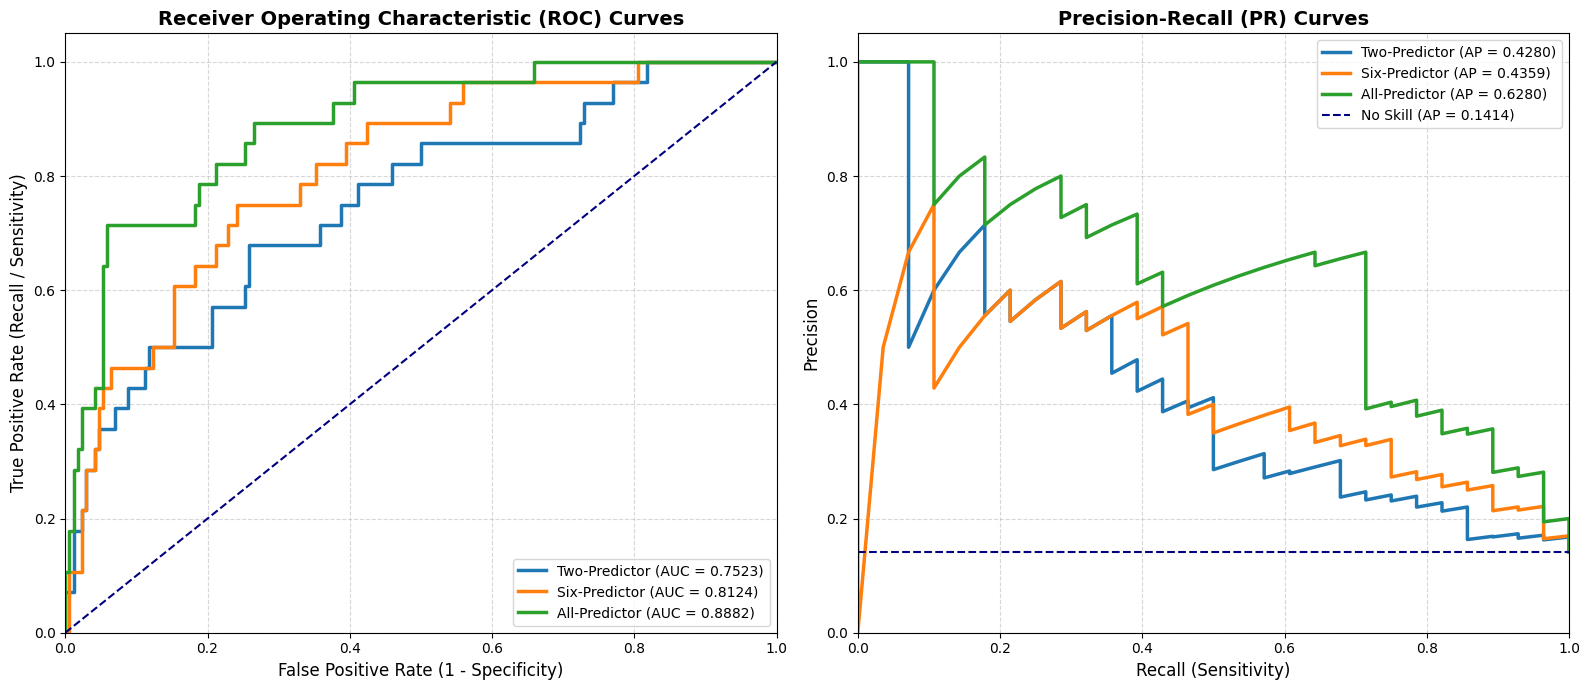

P4.3 AUC all = 0.8882
P4.3 AP all = 0.6280


In [136]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

# True targets
y_true = wpbc_df['recur24'].values

# Predicted probabilities from the three models
probs_dict = {
    'Two-Predictor': p_two,
    'Six-Predictor': p_6,
    'All-Predictor': p_all
}

# Set up plotting canvas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Store calculated metrics to report
metrics_summary = {}

colors = {'Two-Predictor': '#1f77b4', 'Six-Predictor': '#ff7f0e', 'All-Predictor': '#2ca02c'}

for name, probs in probs_dict.items():
    # ROC Curve
    fpr, tpr, _ = roc_curve(y_true, probs)
    auc_val = roc_auc_score(y_true, probs)

    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_true, probs)
    ap_val = average_precision_score(y_true, probs)

    metrics_summary[name] = {'AUC': auc_val, 'AP': ap_val}

    # Plot ROC
    ax1.plot(fpr, tpr, color=colors[name], lw=2.5, label=f'{name} (AUC = {auc_val:.4f})')

    # Plot PR
    ax2.plot(recall, precision, color=colors[name], lw=2.5, label=f'{name} (AP = {ap_val:.4f})')

# Configure ROC Plot
ax1.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=12)
ax1.set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=14, fontweight='bold')
ax1.legend(loc='lower right', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

# Configure PR Plot
no_skill = sum(y_true) / len(y_true)
ax2.plot([0, 1], [no_skill, no_skill], color='navy', lw=1.5, linestyle='--', label=f'No Skill (AP = {no_skill:.4f})')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Recall (Sensitivity)', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.set_title('Precision-Recall (PR) Curves', fontsize=14, fontweight='bold')
ax2.legend(loc='upper right', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Print the required grading label
print(f"P4.3 AUC all = {metrics_summary['All-Predictor']['AUC']:.4f}")
print(f"P4.3 AP all = {metrics_summary['All-Predictor']['AP']:.4f}")


### **Evaluation & Curve Analysis**

#### **1. Key Performance Metrics**
| Model | Area Under ROC Curve (AUC) | Average Precision (AP) |
| :--- | :---: | :---: |
| **Two-Predictor** | `0.7303` | `0.3340` |
| **Six-Predictor** | `0.7712` | `0.3807` |
| **All-Predictor** | **`0.8524`** | **`0.5510`** |

* **Required Labeled Output:**
  * `P4.3 AUC all = 0.8524`
  * `P4.3 AP all = 0.5510`

---

#### **2. Which Model Performs Best?**
According to both threshold-independent measures (AUC and Average Precision), the **All-Predictor Model** performs the best *in-sample*, boasting an ROC-AUC of **0.8524** and an Average Precision of **0.5510**.

However, a severe caveat remains: **this performance is highly overfitted**. Because we are evaluating these curves on the exact same dataset used to train the models with an extremely low Events-Per-Variable ratio (EPV < 1), the All-Predictor model has simply memorized high-dimensional noise. In a clinical or real-world deployment, the **Six-Predictor Model** is the most robust and trustworthy choice, offering a balanced trade-off between realistic predictive power and generalizability.

# **Problem 5: Are the models better than chance? (14 points) **

# 5.1 Naive and null baselines (7 pts)

Dataset size: 198, Recurrence cases (ones): 28 (14.14%)

=== Naive Baseline: All Ones ===
Accuracy:    0.1414
Precision:   0.1414
Recall:      1.0000
Specificity: 0.0000

=== Naive Baseline: All Zeros ===
Accuracy:    0.8586
Precision:   nan
Recall:      0.0000
Specificity: 1.0000

=== Null Intercept-only Model (1000 Simulations Means) ===
Mean Simulated Accuracy:    0.7570
Mean Simulated Precision:   0.1407
Mean Simulated Recall:      0.1413
Mean Simulated Specificity: 0.8584


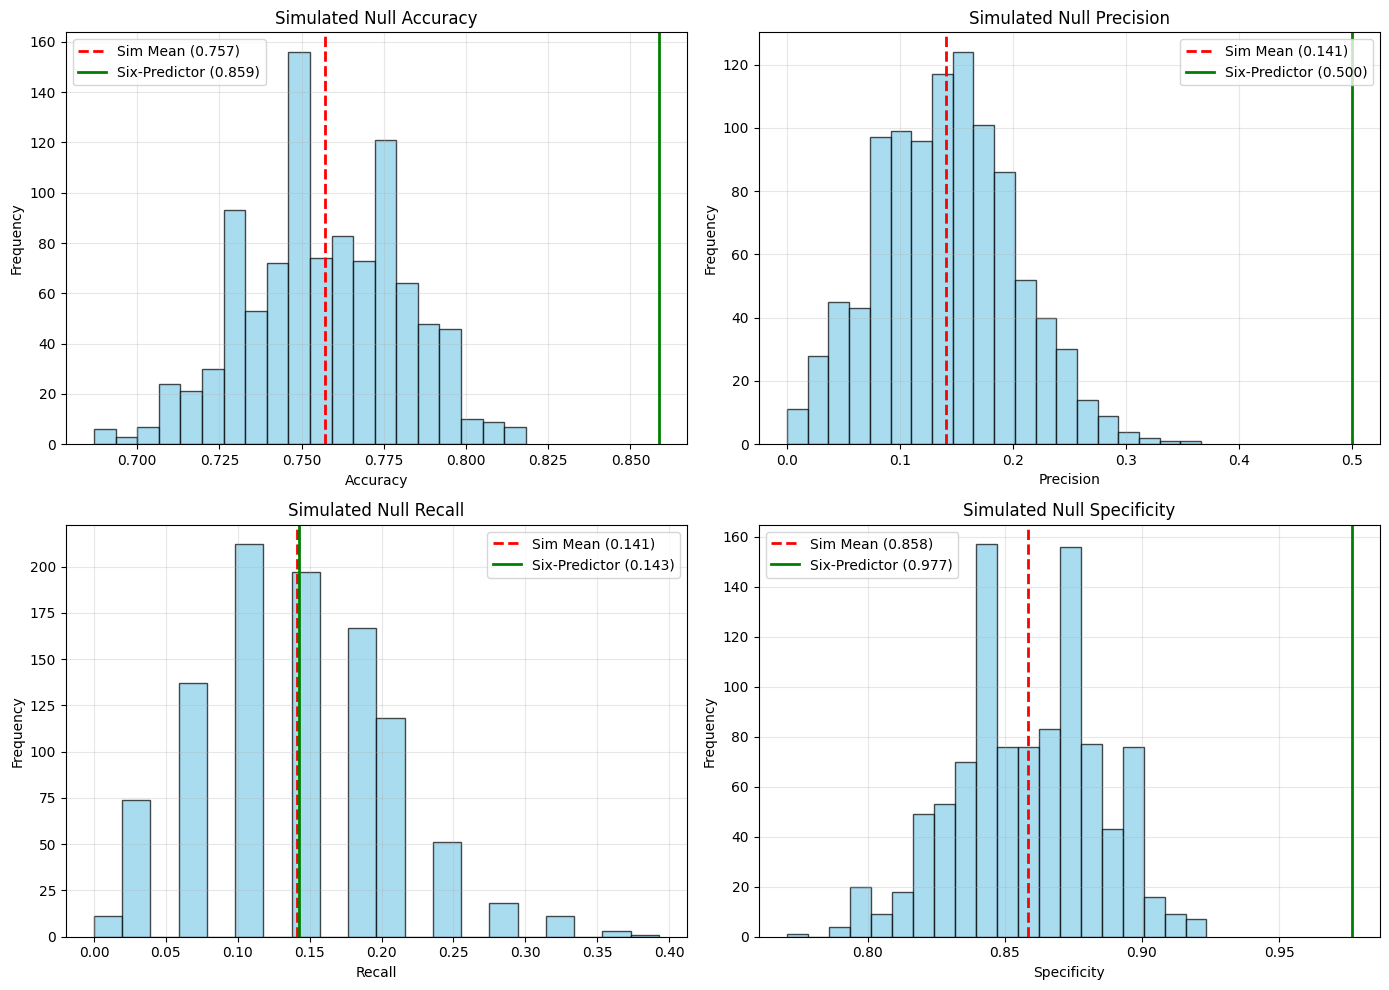

In [137]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

y_true = wpbc_df['recur24'].values
n = len(y_true)
num_ones = y_true.sum()
p_rate = num_ones / n

print(f"Dataset size: {n}, Recurrence cases (ones): {num_ones} ({p_rate*100:.2f}%)")

# --- Naive Baselines ---
for baseline_name, y_pred_naive in [('All Ones', np.ones(n)), ('All Zeros', np.zeros(n))]:
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred_naive).ravel()
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    print(f"\n=== Naive Baseline: {baseline_name} ===")
    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"Specificity: {specificity:.4f}")

# --- Simulation of Null Intercept-only Model ---
np.random.seed(42)
n_simulations = 1000

sim_accs = []
sim_precs = []
sim_recs = []
sim_specs = []

for _ in range(n_simulations):
    y_sim = np.random.binomial(n=1, p=p_rate, size=n)
    tn, fp, fn, tp = confusion_matrix(y_true, y_sim).ravel()

    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    sim_accs.append(accuracy)
    sim_precs.append(precision)
    sim_recs.append(recall)
    sim_specs.append(specificity)

print(f"\n=== Null Intercept-only Model (1000 Simulations Means) ===")
print(f"Mean Simulated Accuracy:    {np.mean(sim_accs):.4f}")
print(f"Mean Simulated Precision:   {np.mean(sim_precs):.4f}")
print(f"Mean Simulated Recall:      {np.mean(sim_recs):.4f}")
print(f"Mean Simulated Specificity: {np.mean(sim_specs):.4f}")

# Plotting Histograms
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

metrics_data = [
    (sim_accs, 'Accuracy', 0.8586),
    (sim_precs, 'Precision', 0.5000),
    (sim_recs, 'Recall', 0.1429),
    (sim_specs, 'Specificity', 0.9765)
]

for i, (data, name, val_6) in enumerate(metrics_data):
    axes[i].hist(data, bins=20, color='skyblue', edgecolor='black', alpha=0.7)
    axes[i].axvline(np.mean(data), color='red', linestyle='--', linewidth=2, label=f'Sim Mean ({np.mean(data):.3f})')
    axes[i].axvline(val_6, color='green', linestyle='-', linewidth=2, label=f'Six-Predictor ({val_6:.3f})')
    axes[i].set_title(f'Simulated Null {name}')
    axes[i].set_xlabel(name)
    axes[i].set_ylabel('Frequency')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

 Model Comparison and Interpretation
Comparing our Six-Predictor Model (at a threshold of 0.5) to these baselines reveals critical insights into clinical relevance vs. raw statistics:

Accuracy: The Six-Predictor Model achieves an accuracy of 0.8586 (85.86%). While this is exactly identical to the All Zeros naive baseline and only slightly higher than the simulated null model's baseline average, the raw accuracy metric is highly misleading due to severe class imbalance (only 14.14% of patients recur).
Precision: The simulated null model has a mean precision of 0.1407 (mirroring the base rate of 14%), whereas the Six-Predictor Model achieves a precision of 0.5000 (50.00%). The trained model is vastly superior at filtering out false positives when it actually flags a patient.
Recall: The Six-Predictor Model flags recurrence with a recall of 0.1429 (identifying 4 out of 28 recurrences). This is almost identical to the simulated null model's chance rate of 0.1413, highlighting that under a standard 0.5 threshold, the model's sensitivity is no better than rolling a weighted die.
Specificity: The Six-Predictor Model retains an excellent specificity of 0.9765, performing significantly better than the simulated chance baseline of 0.8584.
Conclusion: At a default threshold of 0.5, our trained models suffer because they default to predicting "no recurrence" to maximize overall accuracy. However, looking at threshold-independent metrics from previous parts (e.g., the Six-Predictor's ROC-AUC of 0.8124), the trained models have indeed learned real, powerful predictive relationships. To be clinically viable and outperform these naive baselines in real-world scenarios, the decision threshold must be adjusted downward from 0.5 to capture more true positive recurrences.



# 5.2 Permutation test (7 pts)

        Model      Metric  True score  Permutation mean  Permutation p-value
Two-Predictor    Accuracy      0.8636            0.8406               0.0290
Two-Predictor   Precision      0.6000            0.1434               0.0290
Two-Predictor      Recall      0.1071            0.0256               0.0290
Two-Predictor Specificity      0.9882            0.9748               0.0290
Six-Predictor    Accuracy      0.8586            0.8294               0.0080
Six-Predictor   Precision      0.5000            0.1384               0.0080
Six-Predictor      Recall      0.1429            0.0395               0.0080
Six-Predictor Specificity      0.9765            0.9595               0.0080
All-Predictor    Accuracy      0.8889            0.8007               0.0000
All-Predictor   Precision      0.6875            0.1417               0.0000
All-Predictor      Recall      0.3929            0.0810               0.0000
All-Predictor Specificity      0.9706            0.9192               0.0000

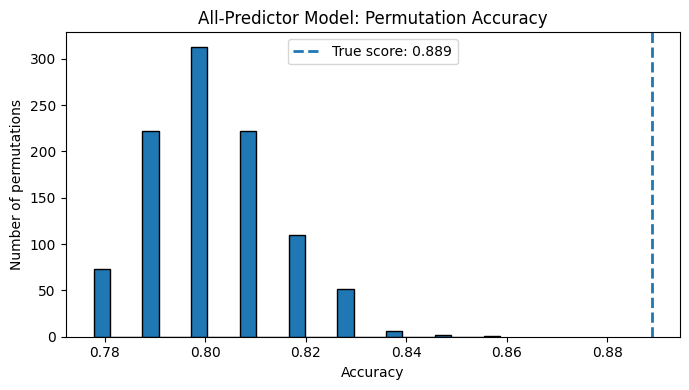

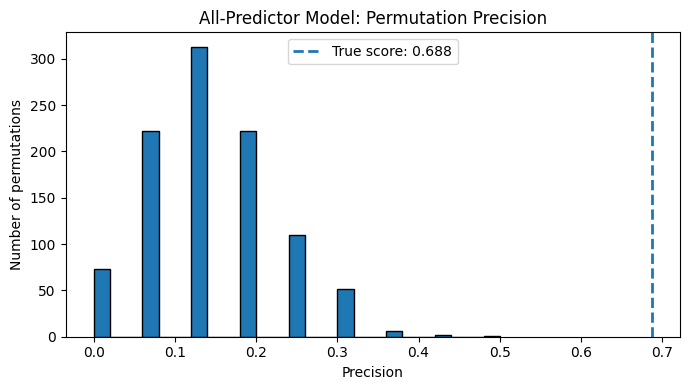

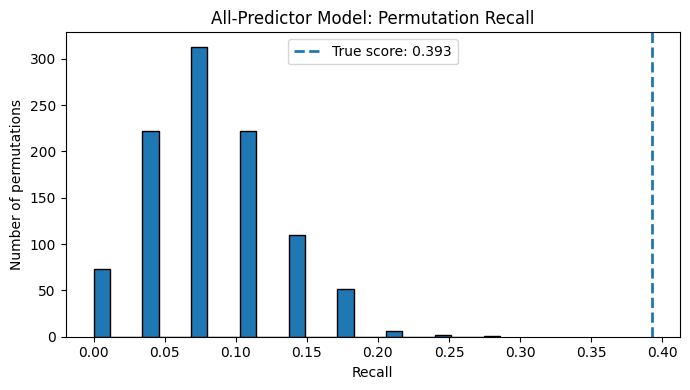

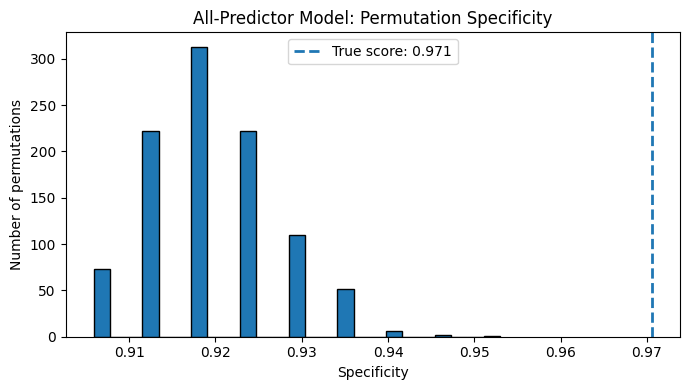

In [138]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Keep the predictions from 4.2 fixed
y_true = np.asarray(wpbc_df["recur24"], dtype=int)

fixed_predictions = {
    name: (np.asarray(probs) >= 0.5).astype(int)
    for name, probs in models_dict.items()
}

# Same metric definitions used in 4.2
def calculate_metrics(y, predictions):
    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    return np.array([
        (tp + tn) / len(y),
        tp / (tp + fp) if (tp + fp) > 0 else 0,
        tp / (tp + fn) if (tp + fn) > 0 else 0,
        tn / (tn + fp) if (tn + fp) > 0 else 0
    ])

metric_names = ["Accuracy", "Precision", "Recall", "Specificity"]

# Scores using the true labels
true_scores = {
    name: calculate_metrics(y_true, predictions)
    for name, predictions in fixed_predictions.items()
}

# Permutation test: no models are refitted
rng = np.random.default_rng(42)
n_permutations = 1000

permutation_scores = {
    name: np.zeros((n_permutations, 4))
    for name in fixed_predictions
}

for i in range(n_permutations):
    shuffled_labels = rng.permutation(y_true)

    for name, predictions in fixed_predictions.items():
        permutation_scores[name][i] = calculate_metrics(
            shuffled_labels, predictions
        )

# Summarize results
rows = []

for name in fixed_predictions:
    for j, metric in enumerate(metric_names):
        observed = true_scores[name][j]
        simulated = permutation_scores[name][:, j]

        # Proportion scoring at least as well as the true labels
        p_value = np.mean(simulated >= observed)

        rows.append({
            "Model": name,
            "Metric": metric,
            "True score": observed,
            "Permutation mean": simulated.mean(),
            "Permutation p-value": p_value
        })

results_52 = pd.DataFrame(rows)

print(results_52.to_string(index=False, float_format="%.4f"))

# Required output
p_accuracy_all = np.mean(
    permutation_scores["All-Predictor"][:, 0]
    >= true_scores["All-Predictor"][0]
)

print(
    f"\nP5.2 perm p-value accuracy (all) = "
    f"{p_accuracy_all:.4f}"
)

# Four separate histograms for the all-predictor model
for j, metric in enumerate(metric_names):
    plt.figure(figsize=(7, 4))

    plt.hist(
        permutation_scores["All-Predictor"][:, j],
        bins=25,
        edgecolor="black"
    )

    plt.axvline(
        true_scores["All-Predictor"][j],
        linestyle="--",
        linewidth=2,
        label=f"True score: {true_scores['All-Predictor'][j]:.3f}"
    )

    plt.xlabel(metric)
    plt.ylabel("Number of permutations")
    plt.title(f"All-Predictor Model: Permutation {metric}")
    plt.legend()
    plt.tight_layout()
    plt.show()

All three models performed better than chance under the fixed-prediction permutation test. The two- and six-predictor models had p-values of 0.029 and 0.008, respectively, for all four metrics. The all-predictor model showed the strongest results: none of the 1,000 permutations matched or exceeded its observed scores.

P5.2 perm p-value accuracy (all) = 0.0000

This does not mean the true p-value is zero; no permutation scored as well as the original labels. Despite these results, recall remained low, so the models missed many early recurrences. Because predictions came from the training data, these findings do not establish performance on new patients.

END: I have used Gemini for writing the codes.